# Pregunta 1
## Carga el conjunto de datos y explora las características disponibles

In [1]:
import numpy as np
import pandas as pd

# 1. Carga de datos desde la fuente oficial
data_url = "http://lib.stat.cmu.edu/datasets/boston"
raw_df = pd.read_csv(data_url, sep=r"\s+", skiprows=22, header=None)

# 2. Formateo de características y variable objetivo
X_data = np.hstack([raw_df.values[::2, :], raw_df.values[1::2, :2]])
y_data = raw_df.values[1::2, 2]

feature_names = ['CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM', 'AGE', 'DIS', 'RAD', 'TAX', 'PTRATIO', 'B', 'LSTAT']
df = pd.DataFrame(X_data, columns=feature_names)
df['MEDV'] = y_data

# 3. Exploración de características y dimensiones
print(f"Dataset cargado correctamente: {df.shape[0]} filas y {df.shape[1]} columnas.")
print("\n--- Primeras 10 filas del dataset ---")
print(df.head(10))
print("\n--- Información general del DataFrame ---")
print(df.info())

print("\n--- Resumen estadístico del dataset ---")
print(df.describe().T[['mean', 'std', 'min', 'max']])

print("\n--- Cantidad de valores nulos por columna ---")
print(df.isnull().sum())

Dataset cargado correctamente: 506 filas y 14 columnas.

--- Primeras 10 filas del dataset ---
      CRIM    ZN  INDUS  CHAS    NOX     RM    AGE     DIS  RAD    TAX  \
0  0.00632  18.0   2.31   0.0  0.538  6.575   65.2  4.0900  1.0  296.0   
1  0.02731   0.0   7.07   0.0  0.469  6.421   78.9  4.9671  2.0  242.0   
2  0.02729   0.0   7.07   0.0  0.469  7.185   61.1  4.9671  2.0  242.0   
3  0.03237   0.0   2.18   0.0  0.458  6.998   45.8  6.0622  3.0  222.0   
4  0.06905   0.0   2.18   0.0  0.458  7.147   54.2  6.0622  3.0  222.0   
5  0.02985   0.0   2.18   0.0  0.458  6.430   58.7  6.0622  3.0  222.0   
6  0.08829  12.5   7.87   0.0  0.524  6.012   66.6  5.5605  5.0  311.0   
7  0.14455  12.5   7.87   0.0  0.524  6.172   96.1  5.9505  5.0  311.0   
8  0.21124  12.5   7.87   0.0  0.524  5.631  100.0  6.0821  5.0  311.0   
9  0.17004  12.5   7.87   0.0  0.524  6.004   85.9  6.5921  5.0  311.0   

   PTRATIO       B  LSTAT  MEDV  
0     15.3  396.90   4.98  24.0  
1     17.8  396.90   9

## Pregunta 2
### Visualiza la distribución del precio de las viviendas y las relaciones entre las características y el precio utilizando gráficos de dispersión u otras visualizaciones pertinentes.

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Calcular la matriz de correlación con la variable objetivo
correlaciones = df.corr()['MEDV'].sort_values(ascending=False)
print("Correlación de los atributos con el precio (MEDV):")
print(correlaciones)

Correlación de los atributos con el precio (MEDV):
MEDV       1.000000
RM         0.695360
ZN         0.360445
B          0.333461
DIS        0.249929
CHAS       0.175260
AGE       -0.376955
RAD       -0.381626
CRIM      -0.388305
NOX       -0.427321
TAX       -0.468536
INDUS     -0.483725
PTRATIO   -0.507787
LSTAT     -0.737663
Name: MEDV, dtype: float64


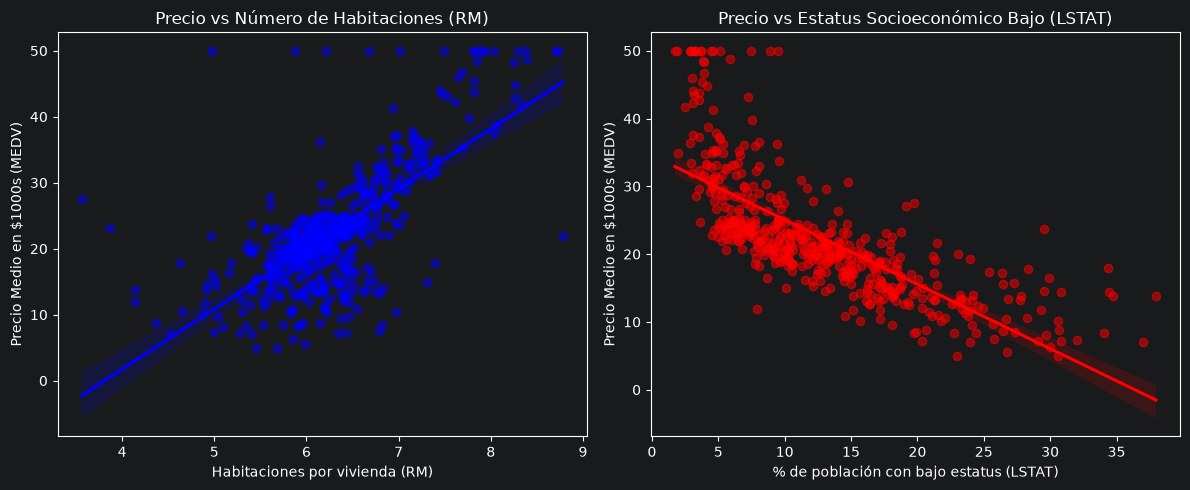

In [3]:
# 2. Generar gráficos de dispersión para las dos variables más críticas: RM y LSTAT
fig, axs = plt.subplots(1, 2, figsize=(12, 5))

# Relación con el número de habitaciones (RM)
sns.regplot(data=df, x='RM', y='MEDV', ax=axs[0], color='blue', scatter_kws={'alpha':0.5})
axs[0].set_title('Precio vs Número de Habitaciones (RM)')
axs[0].set_xlabel('Habitaciones por vivienda (RM)')
axs[0].set_ylabel('Precio Medio en $1000s (MEDV)')

# Relación con el porcentaje de población de bajo estatus (LSTAT)
sns.regplot(data=df, x='LSTAT', y='MEDV', ax=axs[1], color='red', scatter_kws={'alpha':0.5})
axs[1].set_title('Precio vs Estatus Socioeconómico Bajo (LSTAT)')
axs[1].set_xlabel('% de población con bajo estatus (LSTAT)')
axs[1].set_ylabel('Precio Medio en $1000s (MEDV)')

plt.tight_layout()
plt.show()

## Pregunta 3
### Divide el conjunto de datos en características (variables independientes) y la variable objetivo (precio de la vivienda).

In [4]:
X = df.drop(columns=['MEDV'])
y = df['MEDV']

print(f"Características independientes (X): {X.shape[1]} columnas.")
print(f"Variable objetivo (y): {y.shape} (Precios de las viviendas).")

Características independientes (X): 13 columnas.
Variable objetivo (y): (506,) (Precios de las viviendas).


## Pregunta 4
### Divide el conjunto de datos en conjuntos de entrenamiento y prueba.

In [5]:
from sklearn.model_selection import train_test_split

#Divisón de los datos en entrenamiento (80%) y prueba (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Entrenamiento: X_train {X_train.shape}, y_train {y_train.shape}")
print(f"Prueba (Test): X_test {X_test.shape}, y_test {y_test.shape}")

Entrenamiento: X_train (404, 13), y_train (404,)
Prueba (Test): X_test (102, 13), y_test (102,)


## Regresión Lineal Simple

In [6]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# 1. Seleccionar únicamente la variable 'RM' para entrenamiento y prueba
X_train_simple = X_train[['RM']]
X_test_simple = X_test[['RM']]

# 2. Inicializar y entrenar el modelo
lr_simple = LinearRegression()
lr_simple.fit(X_train_simple, y_train)

# 3. Realizar predicciones sobre el conjunto de test
y_pred_simple = lr_simple.predict(X_test_simple)

# 4. Calcular métricas de rendimiento
mse_simple = mean_squared_error(y_test, y_pred_simple)
r2_simple = r2_score(y_test, y_pred_simple)

print("--- RESULTADOS REGRESIÓN LINEAL SIMPLE ---")
print(f"Coeficiente (Pendiente): {lr_simple.coef_[0]:.4f}")
print(f"Intersección (Sesgo): {lr_simple.intercept_:.4f}")
print(f"Error Cuadrático Medio (MSE): {mse_simple:.4f}")
print(f"Coeficiente de Determinación (R²): {r2_simple:.4f}")

--- RESULTADOS REGRESIÓN LINEAL SIMPLE ---
Coeficiente (Pendiente): 9.3483
Intersección (Sesgo): -36.2463
Error Cuadrático Medio (MSE): 46.1448
Coeficiente de Determinación (R²): 0.3708


## Regresión Lineal Múltiple

In [7]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# 1. Inicializar y entrenar el modelo utilizando todas las variables (X_train)
lr_multiple = LinearRegression()
lr_multiple.fit(X_train, y_train)

# 2. Realizar predicciones sobre el conjunto de test (X_test)
y_pred_multiple = lr_multiple.predict(X_test)

# 3. Calcular métricas de rendimiento
mse_multiple = mean_squared_error(y_test, y_pred_multiple)
r2_multiple = r2_score(y_test, y_pred_multiple)

print("--- RESULTADOS REGRESIÓN LINEAL MÚLTIPLE ---")
print(f"Error Cuadrático Medio (MSE): {mse_multiple:.4f}")
print(f"Coeficiente de Determinación (R²): {r2_multiple:.4f}")

--- RESULTADOS REGRESIÓN LINEAL MÚLTIPLE ---
Error Cuadrático Medio (MSE): 24.2911
Coeficiente de Determinación (R²): 0.6688


## Árbol de Regresión

In [8]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error, r2_score

# Ajuste de parámetros: Probamos una profundidad muy baja (2) versus una óptima (5)
for depth in [2, 5]:
    # 1. Inicializar y entrenar el árbol con la profundidad indicada
    tree_model = DecisionTreeRegressor(max_depth=depth, random_state=42)
    tree_model.fit(X_train, y_train)
    
    # 2. Realizar predicciones
    y_pred_tree = tree_model.predict(X_test)
    
    # 3. Calcular métricas
    mse_tree = mean_squared_error(y_test, y_pred_tree)
    r2_tree = r2_score(y_test, y_pred_tree)
    
    print(f"--- ÁRBOL DE REGRESIÓN (max_depth={depth}) ---")
    print(f"Error Cuadrático Medio (MSE): {mse_tree:.4f}")
    print(f"Coeficiente de Determinación (R²): {r2_tree:.4f}\n")

--- ÁRBOL DE REGRESIÓN (max_depth=2) ---
Error Cuadrático Medio (MSE): 25.9932
Coeficiente de Determinación (R²): 0.6455

--- ÁRBOL DE REGRESIÓN (max_depth=5) ---
Error Cuadrático Medio (MSE): 8.5539
Coeficiente de Determinación (R²): 0.8834



## Predicción de más de una variable (MEDV y CRIM)

In [9]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

# 1. Definir las dos variables objetivo: MEDV y CRIM
y_multi = df[['MEDV', 'CRIM']]

# 2. Las características independientes serán todas las demás (eliminando MEDV y CRIM)
X_multi = df.drop(columns=['MEDV', 'CRIM'])

# 3. Dividir en entrenamiento y prueba para este experimento específico
X_train_m, X_test_m, y_train_m, y_test_m = train_test_split(X_multi, y_multi, test_size=0.2, random_state=42)

# 4. Entrenar el Árbol de Regresión Multi-salida (usando max_depth=5)
tree_multi = DecisionTreeRegressor(max_depth=5, random_state=42)
tree_multi.fit(X_train_m, y_train_m)

# 5. Realizar predicciones simultáneas
y_pred_multi = tree_multi.predict(X_test_m)

# 6. Evaluar el rendimiento por separado
mse_medv = mean_squared_error(y_test_m['MEDV'], y_pred_multi[:, 0])
r2_medv = r2_score(y_test_m['MEDV'], y_pred_multi[:, 0])

mse_crim = mean_squared_error(y_test_m['CRIM'], y_pred_multi[:, 1])
r2_crim = r2_score(y_test_m['CRIM'], y_pred_multi[:, 1])

print("--- PREDICCIÓN DE MÁS DE UNA VARIABLE ---")
print(f"Objetivo 1 [Precio - MEDV] -> MSE: {mse_medv:.4f}, R²: {r2_medv:.4f}")
print(f"Objetivo 2 [Criminalidad - CRIM] -> MSE: {mse_crim:.4f}, R²: {r2_crim:.4f}")

--- PREDICCIÓN DE MÁS DE UNA VARIABLE ---
Objetivo 1 [Precio - MEDV] -> MSE: 10.1403, R²: 0.8617
Objetivo 2 [Criminalidad - CRIM] -> MSE: 66.5988, R²: -0.2087
